# Tiny-YOLO Object Detection on NEU-DET

This notebook implements a Tiny-YOLO architecture from scratch using PyTorch, trained on the NEU-DET steel surface defect dataset using CUDA.


In [2]:
# Install required packages
import subprocess
import sys

packages = ['torch', 'torchvision', 'numpy', 'matplotlib', 'tqdm', 'opencv-python']
for pkg in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
from torchvision.datasets import VOCDetection
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm import tqdm
import cv2
import os

# Check CUDA availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

# ============================================
# RTX 4090 OPTIMIZATIONS
# ============================================

# Enable cuDNN auto-tuner for optimal convolution algorithms
torch.backends.cudnn.benchmark = True
torch.backends.cudnn.enabled = True

# Enable TF32 for faster matrix multiplications on Ampere/Ada GPUs
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# Set float32 matmul precision to high for better performance
torch.set_float32_matmul_precision('high')


Using device: cuda
GPU: NVIDIA GeForce RTX 4090
CUDA Version: 13.0
VRAM: 23.5 GB

✓ RTX 4090 Optimizations Enabled:
  - cuDNN benchmark mode
  - TF32 tensor cores
  - High precision matmul


/home/researchadmin/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Configuration Parameters

In [4]:
# Tiny-YOLO Configuration 
IMAGE_SIZE = 416          # Input image size
GRID_SIZE = 13            # Output grid size (416/32)
NUM_CLASSES = 6           # NEU-DET has 6 defect classes
IN_CHANNELS = 1           # NEU-DET images are grayscale (annotation depth = 1)
NUM_ANCHORS = 5           # Number of anchor boxes per grid cell

# Anti-Overfitting
BATCH_SIZE = 16           # Smaller batch = more regularization, better generalization
NUM_WORKERS = 4           # More workers for faster data loading
LEARNING_RATE = 1e-4      # Lower LR for more stable training
NUM_EPOCHS = 100          # Total epochs
WARMUP_EPOCHS = 3         # Warmup period
PATIENCE = 15             # Early stopping patience

# Loss weights - Prioritize IoU
LAMBDA_COORD = 5.0        # Weight for coordinate loss
LAMBDA_NOOBJ = 0.5        # Weight for no-object loss
LAMBDA_IOU = 2.0          # Weight for IoU loss (NEW - prioritize IoU)

# Regularization
DROPOUT_RATE = 0.3        # Dropout for regularization
WEIGHT_DECAY = 5e-4       # L2 regularization

# Data Augmentation
USE_AUGMENTATION = True   # Enable data augmentation
AUG_HSV_H = 0.015         # Hue augmentation
AUG_HSV_S = 0.7           # Saturation augmentation  
AUG_HSV_V = 0.4           # Value augmentation
AUG_FLIP_P = 0.5          # Horizontal flip probability
AUG_SCALE = (0.8, 1.2)    # Random scale range

# Mixed Precision Training (FP16)
USE_AMP = True            # Automatic Mixed Precision for ~2x speedup

# NEU-DET defect classes (6 classes)
NEU_CLASSES = [
    'crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches'
]
NEU_CLASS_TO_IDX = {name: idx for idx, name in enumerate(NEU_CLASSES)}

# Anchor boxes (width, height) - normalized to grid cell
ANCHORS = torch.tensor([
    [1.08, 1.19],
    [3.42, 4.41],
    [6.63, 11.38],
    [9.42, 5.11],
    [16.62, 10.52]
]).to(device)

print(f"  Image Size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"  Batch Size: {BATCH_SIZE} (smaller for better generalization)")
print(f"  Learning Rate: {LEARNING_RATE}")
print(f"  Weight Decay: {WEIGHT_DECAY}")
print(f"  Dropout Rate: {DROPOUT_RATE}")
print(f"  IoU Loss Weight: {LAMBDA_IOU}")
print(f"  Data Augmentation: {USE_AUGMENTATION}")
print(f"  Early Stopping Patience: {PATIENCE} epochs")
print(f"  Input channels: {IN_CHANNELS} (grayscale)")
print(f"  Dataset: NEU-DET ({NUM_CLASSES} classes) -> {NEU_CLASSES}")


RTX 4090 Optimized Configuration (IoU-Focused, Anti-Overfitting):
  Image Size: 416x416
  Batch Size: 16 (smaller for better generalization)
  Learning Rate: 0.0001
  Weight Decay: 0.0005
  Dropout Rate: 0.3
  IoU Loss Weight: 2.0
  Data Augmentation: True
  Early Stopping Patience: 15 epochs
  Input channels: 1 (grayscale)
  Dataset: NEU-DET (6 classes) -> ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


## Tiny-YOLO Architecture (Layer by Layer)

In [5]:
class ConvBlock(nn.Module):
    """Convolutional block: Conv2d + BatchNorm + LeakyReLU"""
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        super(ConvBlock, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.leaky = nn.LeakyReLU(0.1, inplace=True)
    
    def forward(self, x):
        return self.leaky(self.bn(self.conv(x)))


class TinyYOLO(nn.Module):
    """
    Tiny-YOLO Architecture with Dropout Regularization
    
    The network consists of:
    - 9 convolutional layers with batch normalization
    - 5 max pooling layers (stride 2) + 1 max pooling layer (stride 1)
    - Dropout layers for regularization (prevents overfitting)
    - Final detection layer
    """
    
    def __init__(self, num_classes=6, num_anchors=5, in_channels=1, dropout_rate=0.3):
        super(TinyYOLO, self).__init__()
        self.num_classes = num_classes
        self.num_anchors = num_anchors
        self.in_channels = in_channels
        self.dropout_rate = dropout_rate
        
        # Layer 0: NEU-DET grayscale input -> 16 filters
        self.conv1 = ConvBlock(in_channels=in_channels, out_channels=16, kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)  # 416 -> 208
        
        # Layer 1: 16 -> 32 filters
        self.conv2 = ConvBlock(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)  # 208 -> 104
        
        # Layer 2: 32 -> 64 filters
        self.conv3 = ConvBlock(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)  # 104 -> 52
        
        # Layer 3: 64 -> 128 filters
        self.conv4 = ConvBlock(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)  # 52 -> 26
        
        # Layer 4: 128 -> 256 filters
        self.conv5 = ConvBlock(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1)
        self.pool5 = nn.MaxPool2d(kernel_size=2, stride=2)  # 26 -> 13
        
        # Dropout after deep layers
        self.dropout1 = nn.Dropout2d(p=dropout_rate)
        
        # Layer 5: 256 -> 512 filters
        self.conv6 = ConvBlock(in_channels=256, out_channels=512, kernel_size=3, stride=1, padding=1)
        self.pad6 = nn.ZeroPad2d((0, 1, 0, 1))
        self.pool6 = nn.MaxPool2d(kernel_size=2, stride=1)
        
        self.dropout2 = nn.Dropout2d(p=dropout_rate)
        
        # Layer 6: 512 -> 1024 filters
        self.conv7 = ConvBlock(in_channels=512, out_channels=1024, kernel_size=3, stride=1, padding=1)
        
        self.dropout3 = nn.Dropout2d(p=dropout_rate)
        
        # Layer 7: 1024 -> 256 filters
        self.conv8 = ConvBlock(in_channels=1024, out_channels=256, kernel_size=1, stride=1, padding=0)
        
        # Layer 8: 256 -> 512 filters
        self.conv9 = ConvBlock(in_channels=256, out_channels=512, kernel_size=3, stride=1, padding=1)
        
        # Detection layer: anchors * (tx, ty, tw, th, objectness + class scores)
        # NEU-DET -> 5 * (5 + 6) = 55 output channels
        self.detection = nn.Conv2d(
            in_channels=512, 
            out_channels=num_anchors * (5 + num_classes), 
            kernel_size=1, stride=1, padding=0
        )
        
        self._initialize_weights()
    
    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='leaky_relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
    
    def forward(self, x):
        x = self.pool1(self.conv1(x))
        x = self.pool2(self.conv2(x))
        x = self.pool3(self.conv3(x))
        x = self.pool4(self.conv4(x))
        x = self.pool5(self.conv5(x))
        x = self.dropout1(x)
        
        x = self.pool6(self.pad6(self.conv6(x)))
        x = self.dropout2(x)
        
        x = self.conv7(x)
        x = self.dropout3(x)
        
        x = self.conv8(x)
        x = self.conv9(x)
        x = self.detection(x)
        return x

# Create model with dropout
model = TinyYOLO(num_classes=NUM_CLASSES, num_anchors=NUM_ANCHORS, in_channels=IN_CHANNELS, dropout_rate=DROPOUT_RATE).to(device)

out_channels = NUM_ANCHORS * (5 + NUM_CLASSES)
print("Tiny-YOLO Architecture for NEU-DET:")
print("=" * 60)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")
print(f"Input channels: {IN_CHANNELS}")
print(f"Output channels: {NUM_ANCHORS} x (5 + {NUM_CLASSES}) = {out_channels}")
print(f"Dropout Rate: {DROPOUT_RATE}")
print("=" * 60)

# Test forward pass
test_input = torch.randn(1, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE).to(device)
test_output = model(test_input)
print(f"Input shape: {test_input.shape}")
print(f"Output shape: {test_output.shape}")
assert test_output.shape == (1, NUM_ANCHORS * (5 + NUM_CLASSES), GRID_SIZE, GRID_SIZE)


Tiny-YOLO Architecture for NEU-DET (with Dropout Regularization):
Total parameters: 7,765,671
Input channels: 1
Output channels: 5 x (5 + 6) = 55
Dropout Rate: 0.3
Input shape: torch.Size([1, 1, 416, 416])
Output shape: torch.Size([1, 55, 13, 13])
✓ Output shape verified!


## NEU-DET Dataset Loader


In [6]:
import os
import random
import xml.etree.ElementTree as ET
from collections import Counter
from PIL import Image, ImageEnhance

# ============================================
# NEU-DET DATASET (steel surface defects)
#
# Layout (Pascal-VOC style XML annotations):
#   NEU-DET/
#     train/        | validation/
#       images/<class_name>/<class_name>_<n>.jpg
#       annotations/<class_name>_<n>.xml
# ============================================
DATASET_PATH = './NEU-DET'
DATASET_PATH_EXPANDED = os.path.abspath(os.path.expanduser(DATASET_PATH))

print(f"Dataset directory: {DATASET_PATH_EXPANDED}")

# Verify dataset exists
for split in ('train', 'validation'):
    split_dir = os.path.join(DATASET_PATH_EXPANDED, split)
    if os.path.isdir(os.path.join(split_dir, 'images')) and os.path.isdir(os.path.join(split_dir, 'annotations')):
        print(f" Found {split}/images and {split}/annotations")
    else:
        raise FileNotFoundError(f"NEU-DET split '{split}' not found at {split_dir}")

ANCHORS_CPU = torch.tensor([
    [1.08, 1.19], [3.42, 4.41], [6.63, 11.38], [9.42, 5.11], [16.62, 10.52]
])

# Grayscale NEU-DET statistics
if IN_CHANNELS == 1:
    NORM_MEAN, NORM_STD = [0.449], [0.226]
else:
    NORM_MEAN, NORM_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


class NEUDETDataset(Dataset):
    """
    NEU-DET Dataset with Data Augmentation for YOLO training
    
    Images are grayscale (loaded as 1-channel when in_channels == 1).
    Bounding boxes are read from the VOC XML files as [x, y, w, h, class_idx].
    
    Augmentations (train only):
    - Random horizontal flip (50%)
    - Brightness / contrast jitter (colour jitter is skipped for grayscale)
    - Random scale (80%-120%)
    """
    
    IMAGE_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')
    
    def __init__(self, root, split='train',
                 image_size=416, grid_size=13, num_classes=6, num_anchors=5,
                 anchors=None, augment=False, in_channels=1):
        self.root = os.path.join(os.path.abspath(os.path.expanduser(root)), split)
        self.images_dir = os.path.join(self.root, 'images')
        self.annotations_dir = os.path.join(self.root, 'annotations')
        self.split = split
        self.image_size = image_size
        self.grid_size = grid_size
        self.num_classes = num_classes
        self.num_anchors = num_anchors
        self.anchors = anchors.cpu() if anchors.is_cuda else anchors
        self.augment = augment
        self.in_channels = in_channels
        
        if in_channels == 1:
            self.pil_mode = 'L'
            self.normalize = transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
        else:
            self.pil_mode = 'RGB'
            self.normalize = transforms.Normalize(mean=NORM_MEAN, std=NORM_STD)
        
        self.samples = self._index_samples()
        
        print(f"Loaded {len(self.samples)} {split} images | Augmentation: {'ON' if augment else 'OFF'}")
    
    # ---------- indexing / parsing ----------
    def _find_image(self, stem):
        # Images live in a sub-folder named after the class: "crazing_12" -> images/crazing/crazing_12.jpg
        class_dir = stem.rsplit('_', 1)[0]
        for ext in self.IMAGE_EXTS:
            path = os.path.join(self.images_dir, class_dir, stem + ext)
            if os.path.exists(path):
                return path
        return None
    
    def _parse_annotation(self, ann_path):
        root = ET.parse(ann_path).getroot()
        bboxes = []
        for obj in root.findall('object'):
            name = obj.find('name').text.strip()
            if name not in NEU_CLASS_TO_IDX:
                continue
            bb = obj.find('bndbox')
            xmin = float(bb.find('xmin').text)
            ymin = float(bb.find('ymin').text)
            xmax = float(bb.find('xmax').text)
            ymax = float(bb.find('ymax').text)
            w, h = xmax - xmin, ymax - ymin
            if w > 0 and h > 0:
                bboxes.append([xmin, ymin, w, h, NEU_CLASS_TO_IDX[name]])
        return bboxes
    
    def _index_samples(self):
        samples = []
        skipped_no_image, skipped_no_box = 0, 0
        for ann_name in sorted(os.listdir(self.annotations_dir)):
            if not ann_name.lower().endswith('.xml'):
                continue
            stem = os.path.splitext(ann_name)[0]
            img_path = self._find_image(stem)
            if img_path is None:
                skipped_no_image += 1
                continue
            bboxes = self._parse_annotation(os.path.join(self.annotations_dir, ann_name))
            if len(bboxes) == 0:
                skipped_no_box += 1
                continue
            samples.append((img_path, bboxes))
        if skipped_no_image or skipped_no_box:
            print(f" {self.split}: skipped {skipped_no_image} annotations without an image, "
                  f"{skipped_no_box} without valid boxes")
        return samples
    
    def class_counts(self):
        counts = Counter()
        for _, bboxes in self.samples:
            for *_, cls in bboxes:
                counts[NEU_CLASSES[cls]] += 1
        return dict(counts)
    
    def __len__(self):
        return len(self.samples)
    
    # ---------- augmentation ----------
    def augment_hsv(self, img):
        """Photometric augmentation (brightness/contrast; colour only for RGB)"""
        if random.random() < 0.5:
            img = ImageEnhance.Brightness(img).enhance(1.0 + random.uniform(-AUG_HSV_V, AUG_HSV_V))
        if img.mode == 'RGB' and random.random() < 0.5:
            img = ImageEnhance.Color(img).enhance(1.0 + random.uniform(-AUG_HSV_S, AUG_HSV_S))
        if random.random() < 0.5:
            img = ImageEnhance.Contrast(img).enhance(1.0 + random.uniform(-0.3, 0.3))
        return img
    
    def horizontal_flip(self, img, bboxes):
        """Flip image and bboxes horizontally"""
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
        w = img.size[0]
        return img, [[w - x - bw, y, bw, h, cat] for x, y, bw, h, cat in bboxes]
    
    def random_scale(self, img, bboxes, scale_range=(0.8, 1.2)):
        """Random scale augmentation"""
        orig_w, orig_h = img.size
        scale = random.uniform(*scale_range)
        new_w, new_h = int(orig_w * scale), int(orig_h * scale)
        img = img.resize((new_w, new_h), Image.BILINEAR)
        
        if scale > 1.0:  # Crop
            left = random.randint(0, new_w - orig_w)
            top = random.randint(0, new_h - orig_h)
            img = img.crop((left, top, left + orig_w, top + orig_h))
            bboxes = [[x * scale - left, y * scale - top, w * scale, h * scale, cat] 
                      for x, y, w, h, cat in bboxes]
        else:  # Pad
            fill = 128 if img.mode == 'L' else (128, 128, 128)
            padded = Image.new(img.mode, (orig_w, orig_h), fill)
            left, top = (orig_w - new_w) // 2, (orig_h - new_h) // 2
            padded.paste(img, (left, top))
            img = padded
            bboxes = [[x * scale + left, y * scale + top, w * scale, h * scale, cat] 
                      for x, y, w, h, cat in bboxes]
        
        # Filter valid bboxes
        bboxes = [[x, y, w, h, cat] for x, y, w, h, cat in bboxes 
                  if x + w > 0 and y + h > 0 and x < orig_w and y < orig_h and w > 2 and h > 2]
        return img, bboxes
    
    # ---------- item ----------
    def __getitem__(self, idx):
        img_path, bboxes = self.samples[idx]
        img = Image.open(img_path).convert(self.pil_mode)
        bboxes = [list(b) for b in bboxes]  # copy so augmentation never mutates the cache
        
        # Apply augmentation
        if self.augment and len(bboxes) > 0:
            img = self.augment_hsv(img)
            if random.random() < AUG_FLIP_P:
                img, bboxes = self.horizontal_flip(img, bboxes)
            if random.random() < 0.5:
                img, bboxes = self.random_scale(img, bboxes, AUG_SCALE)
        
        aug_w, aug_h = img.size
        
        # Resize and normalize -> (in_channels, image_size, image_size)
        img = img.resize((self.image_size, self.image_size), Image.BILINEAR)
        img = self.normalize(transforms.ToTensor()(img))
        
        # Create target tensor
        target = torch.zeros(self.grid_size, self.grid_size, self.num_anchors, 5 + self.num_classes)
        
        for x, y, w, h, class_idx in bboxes:
            x_center = (x + w / 2) / aug_w
            y_center = (y + h / 2) / aug_h
            width = w / aug_w
            height = h / aug_h
            
            x_center = min(max(x_center, 0), 0.999)
            y_center = min(max(y_center, 0), 0.999)
            
            grid_x = int(x_center * self.grid_size)
            grid_y = int(y_center * self.grid_size)
            grid_x = min(max(grid_x, 0), self.grid_size - 1)
            grid_y = min(max(grid_y, 0), self.grid_size - 1)
            
            # Find best anchor
            box_wh = torch.tensor([width * self.grid_size, height * self.grid_size])
            best_anchor = 0
            best_iou = 0
            for a_idx, anchor in enumerate(self.anchors):
                inter = min(box_wh[0], anchor[0]) * min(box_wh[1], anchor[1])
                union = box_wh[0] * box_wh[1] + anchor[0] * anchor[1] - inter
                iou = inter / (union + 1e-6)
                if iou > best_iou:
                    best_iou, best_anchor = iou, a_idx
            
            if target[grid_y, grid_x, best_anchor, 4] == 0:
                target[grid_y, grid_x, best_anchor, 0] = x_center * self.grid_size - grid_x
                target[grid_y, grid_x, best_anchor, 1] = y_center * self.grid_size - grid_y
                target[grid_y, grid_x, best_anchor, 2] = width * self.grid_size
                target[grid_y, grid_x, best_anchor, 3] = height * self.grid_size
                target[grid_y, grid_x, best_anchor, 4] = 1.0
                target[grid_y, grid_x, best_anchor, 5 + class_idx] = 1.0
        
        return img, target


# Create datasets
print(f"\nLoading NEU-DET datasets...")

train_dataset = NEUDETDataset(
    root=DATASET_PATH, split='train',
    image_size=IMAGE_SIZE, grid_size=GRID_SIZE,
    num_classes=NUM_CLASSES, num_anchors=NUM_ANCHORS, anchors=ANCHORS_CPU,
    augment=USE_AUGMENTATION,  # AUGMENTATION ON for training
    in_channels=IN_CHANNELS
)

val_dataset = NEUDETDataset(
    root=DATASET_PATH, split='validation',
    image_size=IMAGE_SIZE, grid_size=GRID_SIZE,
    num_classes=NUM_CLASSES, num_anchors=NUM_ANCHORS, anchors=ANCHORS_CPU,
    augment=False,  # NO augmentation for validation
    in_channels=IN_CHANNELS
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, 
                          num_workers=NUM_WORKERS, pin_memory=True, 
                          persistent_workers=True, prefetch_factor=4, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True, 
                        persistent_workers=True, prefetch_factor=4)

print(f"\n Dataset loaded!")
print(f"  Training: {len(train_dataset)} samples | Augmentation: {USE_AUGMENTATION}")
print(f"  Validation: {len(val_dataset)} samples")
print(f"  Batches/epoch: {len(train_loader)}")
print(f"  Train boxes per class: {train_dataset.class_counts()}")

# Sanity-check one sample against the model's expected input/output shapes
sample_img, sample_target = train_dataset[0]
print(f"  Sample image: {tuple(sample_img.shape)} | target: {tuple(sample_target.shape)}")
assert sample_img.shape == (IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
assert sample_target.shape == (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, 5 + NUM_CLASSES)


Dataset directory: /mnt/HDD_Backup/korino/finalYearProject/NEU-DET
✓ Found train/images and train/annotations
✓ Found validation/images and validation/annotations

Loading NEU-DET datasets...
Loaded 1439 train images | Augmentation: ON
⚠ validation: skipped 1 annotations without an image, 0 without valid boxes
Loaded 360 validation images | Augmentation: OFF

✓ Dataset loaded!
  Training: 1439 samples | Augmentation: True
  Validation: 360 samples
  Batches/epoch: 89
  Train boxes per class: {'crazing': 524, 'patches': 688, 'inclusion': 852, 'pitted_surface': 345, 'rolled-in_scale': 496, 'scratches': 427}
  Sample image: (1, 416, 416) | target: (13, 13, 5, 11)


## YOLO Loss Function

In [7]:
def compute_ciou(pred_boxes, target_boxes, eps=1e-7):
    """
    Complete IoU (CIoU) - Directly optimizes IoU, center distance, and aspect ratio
    
    CIoU = IoU - (center_distance² / diagonal²) - α*v
    where v measures aspect ratio consistency
    """
    pred_cx, pred_cy = pred_boxes[:, 0], pred_boxes[:, 1]
    pred_w, pred_h = pred_boxes[:, 2].clamp(min=eps), pred_boxes[:, 3].clamp(min=eps)
    
    target_cx, target_cy = target_boxes[:, 0], target_boxes[:, 1]
    target_w, target_h = target_boxes[:, 2].clamp(min=eps), target_boxes[:, 3].clamp(min=eps)
    
    # Convert to corners
    pred_x1, pred_y1 = pred_cx - pred_w/2, pred_cy - pred_h/2
    pred_x2, pred_y2 = pred_cx + pred_w/2, pred_cy + pred_h/2
    target_x1, target_y1 = target_cx - target_w/2, target_cy - target_h/2
    target_x2, target_y2 = target_cx + target_w/2, target_cy + target_h/2
    
    # Intersection
    inter_x1 = torch.max(pred_x1, target_x1)
    inter_y1 = torch.max(pred_y1, target_y1)
    inter_x2 = torch.min(pred_x2, target_x2)
    inter_y2 = torch.min(pred_y2, target_y2)
    inter_area = (inter_x2 - inter_x1).clamp(min=0) * (inter_y2 - inter_y1).clamp(min=0)
    
    # Union
    pred_area = pred_w * pred_h
    target_area = target_w * target_h
    union_area = pred_area + target_area - inter_area + eps
    
    # IoU
    iou = inter_area / union_area
    
    # Enclosing box diagonal
    enclose_x1 = torch.min(pred_x1, target_x1)
    enclose_y1 = torch.min(pred_y1, target_y1)
    enclose_x2 = torch.max(pred_x2, target_x2)
    enclose_y2 = torch.max(pred_y2, target_y2)
    enclose_diag_sq = (enclose_x2 - enclose_x1)**2 + (enclose_y2 - enclose_y1)**2 + eps
    
    # Center distance
    center_dist_sq = (pred_cx - target_cx)**2 + (pred_cy - target_cy)**2
    
    # Aspect ratio term
    v = (4 / (torch.pi**2)) * (torch.atan(pred_w/(pred_h+eps)) - torch.atan(target_w/(target_h+eps)))**2
    
    with torch.no_grad():
        alpha = v / (1 - iou + v + eps)
    
    ciou = iou - center_dist_sq / enclose_diag_sq - alpha * v
    return ciou


class YOLOLossWithCIoU(nn.Module):
    """
    YOLO Loss with CIoU for better bounding box regression
    
    CIoU directly optimizes:
    1. IoU (overlap)
    2. Center distance  
    3. Aspect ratio consistency

    """
    
    def __init__(self, num_classes=80, num_anchors=5, anchors=None, 
                 lambda_coord=5.0, lambda_noobj=0.5, lambda_iou=2.0, label_smoothing=0.1):
        super().__init__()
        self.num_classes = num_classes
        self.num_anchors = num_anchors
        self.anchors = anchors
        self.lambda_coord = lambda_coord
        self.lambda_noobj = lambda_noobj
        self.lambda_iou = lambda_iou
        self.label_smoothing = label_smoothing
        self.bce_loss = nn.BCEWithLogitsLoss(reduction='sum')
    
    def forward(self, predictions, targets):
        batch_size = predictions.size(0)
        grid_size = predictions.size(2)
        
        # Reshape: (B, A, 5+C, G, G) -> (B, G, G, A, 5+C)
        predictions = predictions.view(batch_size, self.num_anchors, 5 + self.num_classes, grid_size, grid_size)
        predictions = predictions.permute(0, 3, 4, 1, 2).contiguous()
        
        pred_xy = torch.sigmoid(predictions[..., :2])
        pred_wh = predictions[..., 2:4]
        pred_conf = predictions[..., 4]
        pred_class = predictions[..., 5:]
        
        target_xy = targets[..., :2]
        target_wh = targets[..., 2:4]
        target_conf = targets[..., 4]
        target_class = targets[..., 5:]
        
        obj_mask = target_conf == 1
        noobj_mask = target_conf == 0
        
        ciou_loss = torch.tensor(0.0, device=predictions.device)
        avg_iou = 0.0
        
        if obj_mask.sum() > 0:
            # Create grid
            grid_y, grid_x = torch.meshgrid(
                torch.arange(grid_size, device=predictions.device),
                torch.arange(grid_size, device=predictions.device), indexing='ij'
            )
            grid_x = grid_x.float().unsqueeze(-1).expand_as(pred_xy[..., 0])
            grid_y = grid_y.float().unsqueeze(-1).expand_as(pred_xy[..., 1])
            
            # Predicted boxes (absolute grid coords)
            pred_cx = (pred_xy[..., 0] + grid_x)[obj_mask]
            pred_cy = (pred_xy[..., 1] + grid_y)[obj_mask]
            
            anchor_w = self.anchors[:, 0].view(1, 1, 1, -1).expand_as(pred_wh[..., 0])
            anchor_h = self.anchors[:, 1].view(1, 1, 1, -1).expand_as(pred_wh[..., 1])
            
            pred_w = (anchor_w * torch.exp(pred_wh[..., 0].clamp(max=10)))[obj_mask]
            pred_h = (anchor_h * torch.exp(pred_wh[..., 1].clamp(max=10)))[obj_mask]
            
            # Target boxes
            target_cx = (target_xy[..., 0] + grid_x)[obj_mask]
            target_cy = (target_xy[..., 1] + grid_y)[obj_mask]
            target_w = target_wh[..., 0][obj_mask]
            target_h = target_wh[..., 1][obj_mask]
            
            pred_boxes = torch.stack([pred_cx, pred_cy, pred_w, pred_h], dim=-1)
            target_boxes = torch.stack([target_cx, target_cy, target_w, target_h], dim=-1)
            
            ciou = compute_ciou(pred_boxes, target_boxes)
            avg_iou = ciou.mean().item()
            ciou_loss = self.lambda_iou * (1 - ciou).sum()
        
        # Confidence loss
        conf_loss = torch.tensor(0.0, device=predictions.device)
        if obj_mask.sum() > 0:
            conf_loss += self.bce_loss(pred_conf[obj_mask], target_conf[obj_mask])
        if noobj_mask.sum() > 0:
            conf_loss += self.lambda_noobj * self.bce_loss(pred_conf[noobj_mask], target_conf[noobj_mask])
        
        # Class loss with label smoothing
        class_loss = torch.tensor(0.0, device=predictions.device)
        if obj_mask.sum() > 0:
            # Apply label smoothing
            smoothed_targets = target_class[obj_mask] * (1 - self.label_smoothing) + self.label_smoothing / self.num_classes
            class_loss = self.bce_loss(pred_class[obj_mask], smoothed_targets)
        
        total_loss = (ciou_loss + conf_loss + class_loss) / batch_size
        
        return total_loss, {
            'ciou_loss': ciou_loss.item() / batch_size,
            'conf_loss': conf_loss.item() / batch_size,
            'class_loss': class_loss.item() / batch_size,
            'avg_iou': avg_iou
        }


# Initialize CIoU loss
criterion = YOLOLossWithCIoU(
    num_classes=NUM_CLASSES,
    num_anchors=NUM_ANCHORS,
    anchors=ANCHORS,
    lambda_coord=LAMBDA_COORD,
    lambda_noobj=LAMBDA_NOOBJ,
    lambda_iou=LAMBDA_IOU,
    label_smoothing=0.1  # Helps with classification
)

print(" YOLO Loss with CIoU initialized")
print(f"  λ_iou: {LAMBDA_IOU} (prioritizes IoU)")
print(f"  λ_noobj: {LAMBDA_NOOBJ}")
print(f"  Label smoothing: 0.1")

✓ YOLO Loss with CIoU initialized
  λ_iou: 2.0 (prioritizes IoU)
  λ_noobj: 0.5
  Label smoothing: 0.1


## Training Loop with CUDA

In [8]:
def train_epoch(model, train_loader, criterion, optimizer, scheduler, scaler, device, epoch):
    """Train one epoch with IoU tracking"""
    model.train()
    total_loss = 0
    total_iou = 0
    loss_components = {'ciou_loss': 0, 'conf_loss': 0, 'class_loss': 0}
    
    pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}')
    for images, targets in pbar:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        
        optimizer.zero_grad(set_to_none=True)
        
        with torch.amp.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            predictions = model(images)
            loss, components = criterion(predictions, targets)
        
        if USE_AMP:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        
        scheduler.step()
        
        total_loss += loss.item()
        total_iou += components.get('avg_iou', 0)
        for k in loss_components:
            loss_components[k] += components.get(k, 0)
        
        pbar.set_postfix({'loss': f'{loss.item():.3f}', 'IoU': f'{components.get("avg_iou", 0):.3f}'})
    
    n = len(train_loader)
    return total_loss/n, {k: v/n for k, v in loss_components.items()}, total_iou/n


def validate(model, val_loader, criterion, device):
    """Validate with IoU tracking"""
    model.eval()
    total_loss = 0
    total_iou = 0
    loss_components = {'ciou_loss': 0, 'conf_loss': 0, 'class_loss': 0}
    
    with torch.no_grad():
        for images, targets in tqdm(val_loader, desc='Validating'):
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            
            with torch.amp.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                predictions = model(images)
                loss, components = criterion(predictions, targets)
            
            total_loss += loss.item()
            total_iou += components.get('avg_iou', 0)
            for k in loss_components:
                loss_components[k] += components.get(k, 0)
    
    n = len(val_loader)
    return total_loss/n, {k: v/n for k, v in loss_components.items()}, total_iou/n


class EarlyStopping:
    """Stop training when validation loss stops improving"""
    def __init__(self, patience=10, min_delta=0.001):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
    
    def __call__(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            return False
        self.counter += 1
        return self.counter >= self.patience


# Optimizer with stronger regularization
optimizer = optim.AdamW(
    model.parameters(), 
    lr=LEARNING_RATE, 
    weight_decay=WEIGHT_DECAY,  # Stronger L2 regularization
    betas=(0.9, 0.999),
    fused=True
)

# Scheduler with warmup
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=LEARNING_RATE * 10,
    total_steps=NUM_EPOCHS * len(train_loader),
    pct_start=WARMUP_EPOCHS / NUM_EPOCHS,
    anneal_strategy='cos',
    div_factor=10,
    final_div_factor=100
)

scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
early_stopping = EarlyStopping(patience=PATIENCE, min_delta=0.01)


print(f"\n Training Setup (Anti-Overfitting):")
print(f"  Optimizer: AdamW (weight_decay={WEIGHT_DECAY})")
print(f"  Early Stopping: patience={PATIENCE}")
print(f"  Dropout: {DROPOUT_RATE}")
print(f"  Data Augmentation: {USE_AUGMENTATION}")


✓ Training Setup (Anti-Overfitting):
  Optimizer: AdamW (weight_decay=0.0005)
  Early Stopping: patience=15
  Dropout: 0.3
  Data Augmentation: True


In [9]:
# Main training loop - IoU Optimized 

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

train_losses, val_losses = [], []
train_ious, val_ious = [], []
best_val_loss = float('inf')
best_val_iou = 0

import time
start_time = time.time()

for epoch in range(NUM_EPOCHS):
    epoch_start = time.time()
    
    train_loss, train_comp, train_iou = train_epoch(
        model, train_loader, criterion, optimizer, scheduler, scaler, device, epoch
    )
    val_loss, val_comp, val_iou = validate(model, val_loader, criterion, device)
    
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_ious.append(train_iou)
    val_ious.append(val_iou)
    
    epoch_time = time.time() - epoch_start
    lr = optimizer.param_groups[0]['lr']
    
    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS} [{epoch_time:.1f}s]")
    print(f"  Train - Loss: {train_loss:.4f} | IoU: {train_iou:.4f} | CIoU: {train_comp['ciou_loss']:.3f}")
    print(f"  Val   - Loss: {val_loss:.4f} | IoU: {val_iou:.4f} | CIoU: {val_comp['ciou_loss']:.3f}")
    print(f"  LR: {lr:.2e} | Gap Ratio: {val_loss/(train_loss+1e-6):.2f}x")
    
    # Save best by loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            'epoch': epoch, 'model_state_dict': model.state_dict(),
            'val_loss': val_loss, 'val_iou': val_iou
        }, 'tiny_yolo_best.pth')
        print(f"   Saved best model (loss: {val_loss:.4f})")
    
    # Save best by IoU
    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save({
            'epoch': epoch, 'model_state_dict': model.state_dict(),
            'val_iou': val_iou
        }, 'tiny_yolo_best_iou.pth')
        print(f"   Saved best IoU model (IoU: {val_iou:.4f})")
    
    # Early stopping
    if early_stopping(val_loss):
        print(f"\n⚠ Early stopping at epoch {epoch+1} - val loss hasn't improved for {PATIENCE} epochs")
        break

total_time = time.time() - start_time
print("\n" + "=" * 70)
print("Training Completed")
print(f"  Time: {total_time/60:.1f} min | Epochs: {len(train_losses)}")
print(f"  Best Val Loss: {best_val_loss:.4f}")
print(f"  Best Val IoU: {best_val_iou:.4f}")
print("=" * 70)

🚀 IoU-Optimized Training with Anti-Overfitting Measures
Improvements Applied:
  ✓ CIoU Loss - Directly optimizes IoU, center distance, aspect ratio
  ✓ Data Augmentation - Flip, HSV jitter, random scale
  ✓ Dropout (30%) - Regularization in deep layers
  ✓ Label Smoothing - Better classification generalization
  ✓ Early Stopping - Prevents overfitting
  ✓ Weight Decay - L2 regularization


Validating: 100%|██████████████████████████████████████████████████████████████████████| 23/23 [00:01<00:00, 19.96it/s]



Epoch 1/100 [11.5s]
  Train - Loss: 168.2654 | IoU: 0.1287 | CIoU: 4.018
  Val   - Loss: 35.7727 | IoU: 0.1533 | CIoU: 4.057
  LR: 3.27e-04 | Gap Ratio: 0.21x
  ✓ Saved best model (loss: 35.7727)
  ✓ Saved best IoU model (IoU: 0.1533)


Validating: 100%|██████████████████████████████████████████████████████████████████████| 23/23 [00:00<00:00, 40.04it/s]



Epoch 2/100 [5.1s]
  Train - Loss: 21.8010 | IoU: 0.2992 | CIoU: 3.240
  Val   - Loss: 21.8249 | IoU: 0.2814 | CIoU: 3.482
  LR: 7.78e-04 | Gap Ratio: 1.00x
  ✓ Saved best model (loss: 21.8249)
  ✓ Saved best IoU model (IoU: 0.2814)


...


Epoch 73/100 [5.0s]
  Train - Loss: 8.7132 | IoU: 0.7153 | CIoU: 1.323
  Val   - Loss: 11.6033 | IoU: 0.7004 | CIoU: 1.418
  LR: 1.80e-04 | Gap Ratio: 1.33x


Validating: 100%|██████████████████████████████████████████████████████████████████████| 23/23 [00:00<00:00, 40.31it/s]



Epoch 74/100 [5.0s]
  Train - Loss: 8.6879 | IoU: 0.7155 | CIoU: 1.324
  Val   - Loss: 11.5308 | IoU: 0.7005 | CIoU: 1.418
  LR: 1.68e-04 | Gap Ratio: 1.33x


Validating: 100%|██████████████████████████████████████████████████████████████████████| 23/23 [00:00<00:00, 41.22it/s]


Epoch 75/100 [5.0s]
  Train - Loss: 8.5243 | IoU: 0.7221 | CIoU: 1.288
  Val   - Loss: 11.4383 | IoU: 0.6990 | CIoU: 1.420
  LR: 1.56e-04 | Gap Ratio: 1.34x

⚠ Early stopping at epoch 75 - val loss hasn't improved for 15 epochs

🎉 Training Complete!
  Time: 6.5 min | Epochs: 75
  Best Val Loss: 11.2016
  Best Val IoU: 0.7035


## Visualize Training Progress

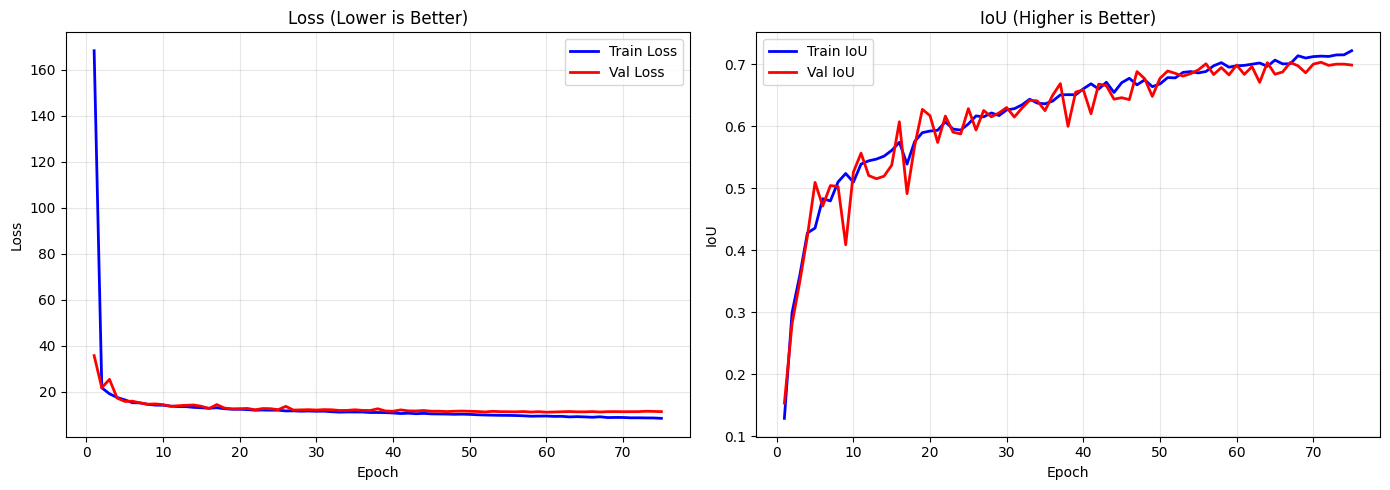


Final Results:
  Train Loss: 8.5243 → Val Loss: 11.4383 (Gap: 1.34x)
  Train IoU: 0.7221 → Val IoU: 0.6990
  Best Val Loss: 11.2016 | Best Val IoU: 0.7035


In [10]:
# Plot training history with IoU
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(train_losses) + 1)

# Loss plot
axes[0].plot(epochs_range, train_losses, 'b-', label='Train Loss', linewidth=2)
axes[0].plot(epochs_range, val_losses, 'r-', label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss (Lower is Better)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# IoU plot
axes[1].plot(epochs_range, train_ious, 'b-', label='Train IoU', linewidth=2)
axes[1].plot(epochs_range, val_ious, 'r-', label='Val IoU', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('IoU')
axes[1].set_title('IoU (Higher is Better)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary
print(f"\nFinal Results:")
print(f"  Train Loss: {train_losses[-1]:.4f} → Val Loss: {val_losses[-1]:.4f} (Gap: {val_losses[-1]/train_losses[-1]:.2f}x)")
print(f"  Train IoU: {train_ious[-1]:.4f} → Val IoU: {val_ious[-1]:.4f}")
print(f"  Best Val Loss: {best_val_loss:.4f} | Best Val IoU: {best_val_iou:.4f}")

## Inference and Visualization

In [12]:
def decode_predictions(predictions, anchors, num_classes, conf_threshold=0.5, nms_threshold=0.4):
    """
    Decode YOLO predictions to bounding boxes
    
    predictions: (batch, num_anchors*(5+num_classes), grid_size, grid_size)
    Returns: List of detections for each image
    """
    batch_size = predictions.size(0)
    grid_size = predictions.size(2)
    num_anchors = anchors.size(0)
    
    # Reshape predictions
    predictions = predictions.view(batch_size, num_anchors, 5 + num_classes, grid_size, grid_size)
    predictions = predictions.permute(0, 3, 4, 1, 2).contiguous()  # (batch, grid, grid, anchors, 5+classes)
    
    all_detections = []
    
    for b in range(batch_size):
        detections = []
        
        for cy in range(grid_size):
            for cx in range(grid_size):
                for a in range(num_anchors):
                    pred = predictions[b, cy, cx, a]
                    
                    # Get confidence
                    conf = torch.sigmoid(pred[4]).item()
                    
                    if conf < conf_threshold:
                        continue
                    
                    # Get class probabilities
                    class_probs = torch.sigmoid(pred[5:])
                    class_score, class_idx = class_probs.max(0)
                    
                    # Final score
                    score = conf * class_score.item()
                    
                    if score < conf_threshold:
                        continue
                    
                    # Decode bounding box
                    tx, ty = torch.sigmoid(pred[0]).item(), torch.sigmoid(pred[1]).item()
                    tw, th = pred[2].item(), pred[3].item()
                    
                    # Convert to absolute coordinates
                    bx = (cx + tx) / grid_size
                    by = (cy + ty) / grid_size
                    bw = anchors[a, 0].item() * np.exp(tw) / grid_size
                    bh = anchors[a, 1].item() * np.exp(th) / grid_size
                    
                    # Convert to corner format (x1, y1, x2, y2)
                    x1 = max(0, bx - bw / 2)
                    y1 = max(0, by - bh / 2)
                    x2 = min(1, bx + bw / 2)
                    y2 = min(1, by + bh / 2)
                    
                    detections.append({
                        'bbox': [x1, y1, x2, y2],
                        'score': score,
                        'class': class_idx.item()
                    })
        
        # Apply NMS
        if len(detections) > 0:
            detections = apply_nms(detections, nms_threshold)
        
        all_detections.append(detections)
    
    return all_detections


def apply_nms(detections, threshold):
    """Apply Non-Maximum Suppression"""
    if len(detections) == 0:
        return []
    
    # Sort by score
    detections = sorted(detections, key=lambda x: x['score'], reverse=True)
    
    keep = []
    while len(detections) > 0:
        best = detections.pop(0)
        keep.append(best)
        
        detections = [d for d in detections if 
                      d['class'] != best['class'] or 
                      compute_iou(best['bbox'], d['bbox']) < threshold]
    
    return keep


def compute_iou(box1, box2):
    """Compute IoU between two boxes"""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    
    inter_area = max(0, x2 - x1) * max(0, y2 - y1)
    box1_area = (box1[2] - box1[0]) * (box1[3] - box1[1])
    box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])
    
    return inter_area / (box1_area + box2_area - inter_area + 1e-6)


def visualize_detections(image, detections, class_names):
    """Visualize detections on image"""
    fig, ax = plt.subplots(1, figsize=(12, 9))
    
    # Denormalize image (1-channel NEU-DET or 3-channel)
    mean = np.array(NORM_MEAN)
    std = np.array(NORM_STD)
    img = image.cpu().numpy().transpose(1, 2, 0)
    img = std * img + mean
    img = np.clip(img, 0, 1)
    if img.shape[-1] == 1:
        img = img.squeeze(-1)
    
    ax.imshow(img, cmap='gray' if img.ndim == 2 else None)
    
    colors = plt.cm.hsv(np.linspace(0, 1, len(class_names)))
    
    for det in detections:
        bbox = det['bbox']
        class_idx = det['class']
        score = det['score']
        
        # Scale bbox to image size
        h, w = img.shape[:2]
        x1, y1 = bbox[0] * w, bbox[1] * h
        x2, y2 = bbox[2] * w, bbox[3] * h
        
        # Draw rectangle
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=colors[class_idx], facecolor='none'
        )
        ax.add_patch(rect)
        
        # Add label
        label = f'{class_names[class_idx]}: {score:.2f}'
        ax.text(x1, y1 - 5, label, color='white', fontsize=10,
                bbox=dict(boxstyle='round', facecolor=colors[class_idx], alpha=0.8))
    
    ax.axis('off')
    plt.tight_layout()
    plt.show()

print("Inference functions defined")


Inference functions defined


Loaded best model from epoch 60
Validation loss: 11.2016

Image 0: Found 3 objects


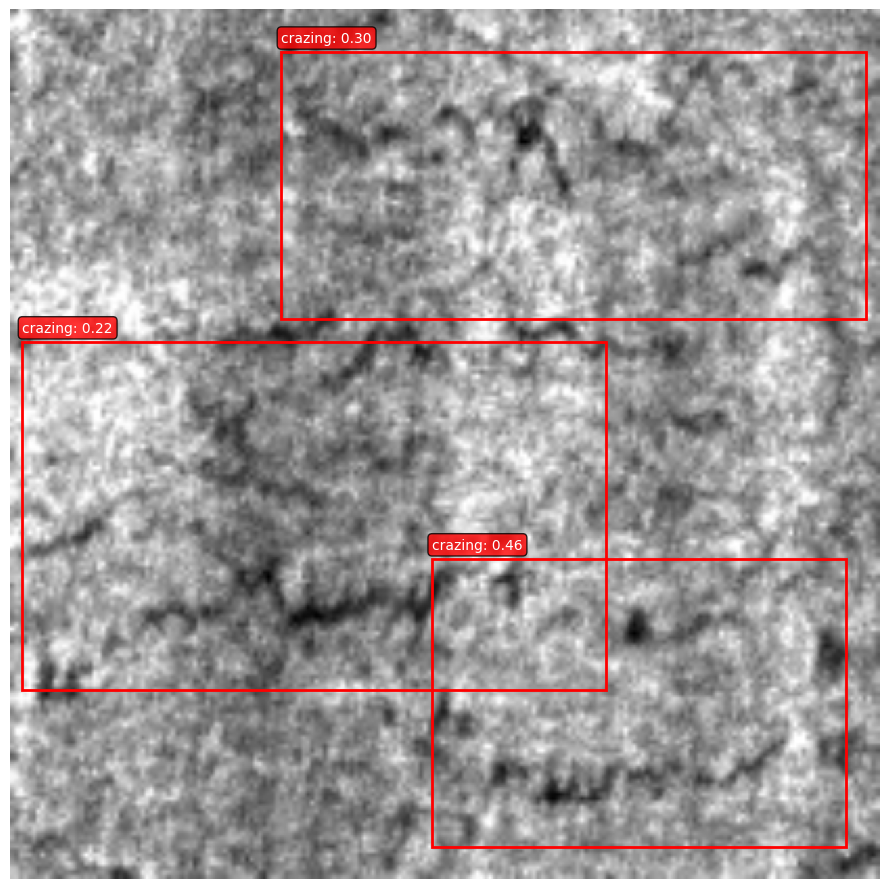


Image 10: Found 1 objects


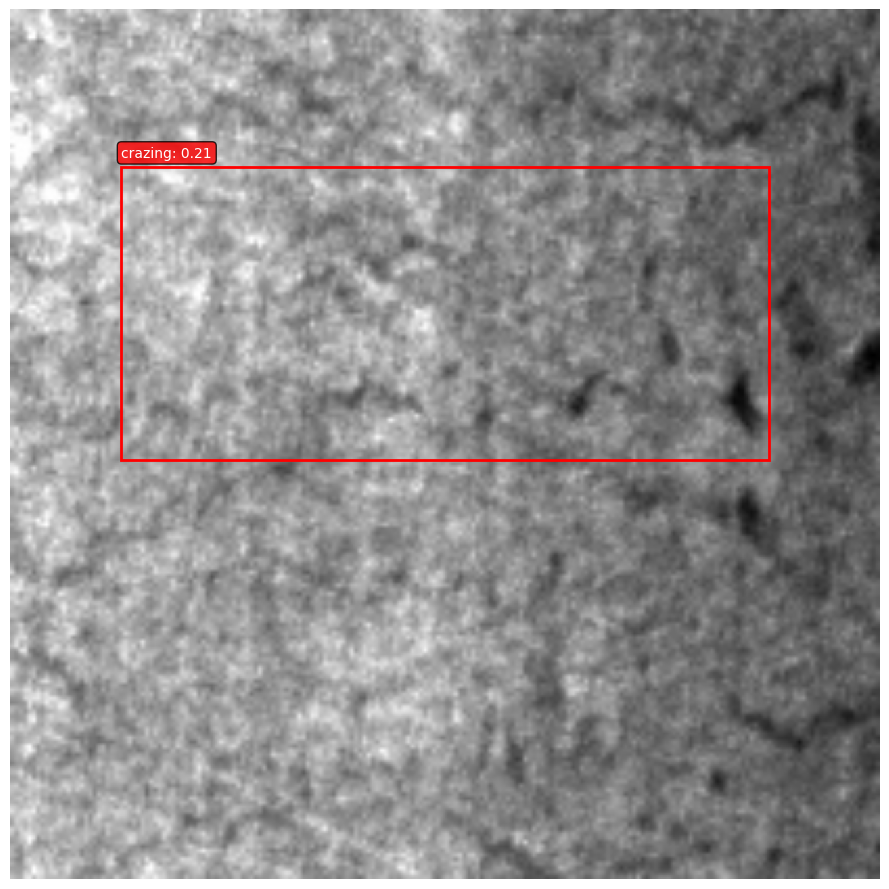


Image 20: Found 2 objects


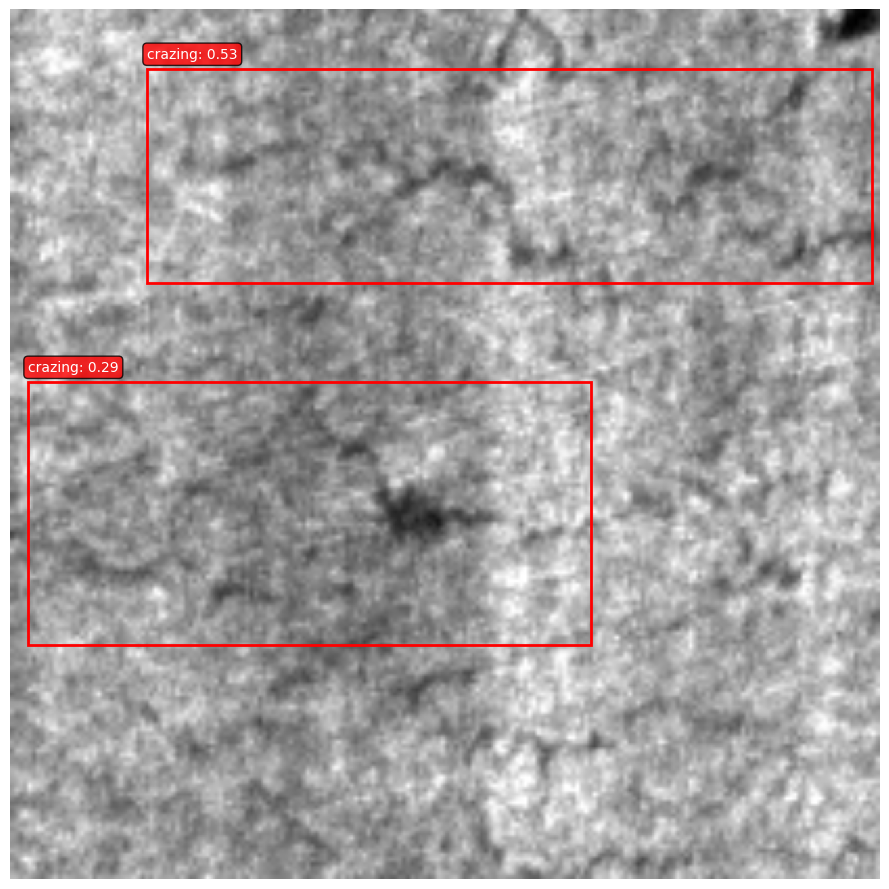


Image 30: Found 3 objects


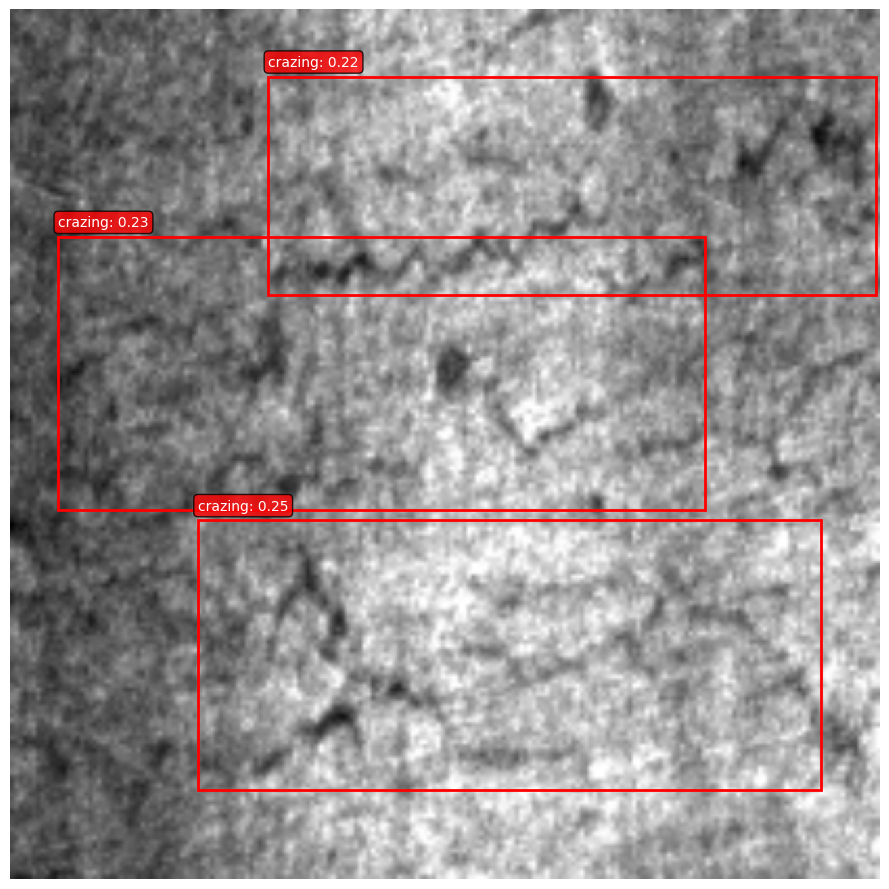


Image 40: Found 0 objects


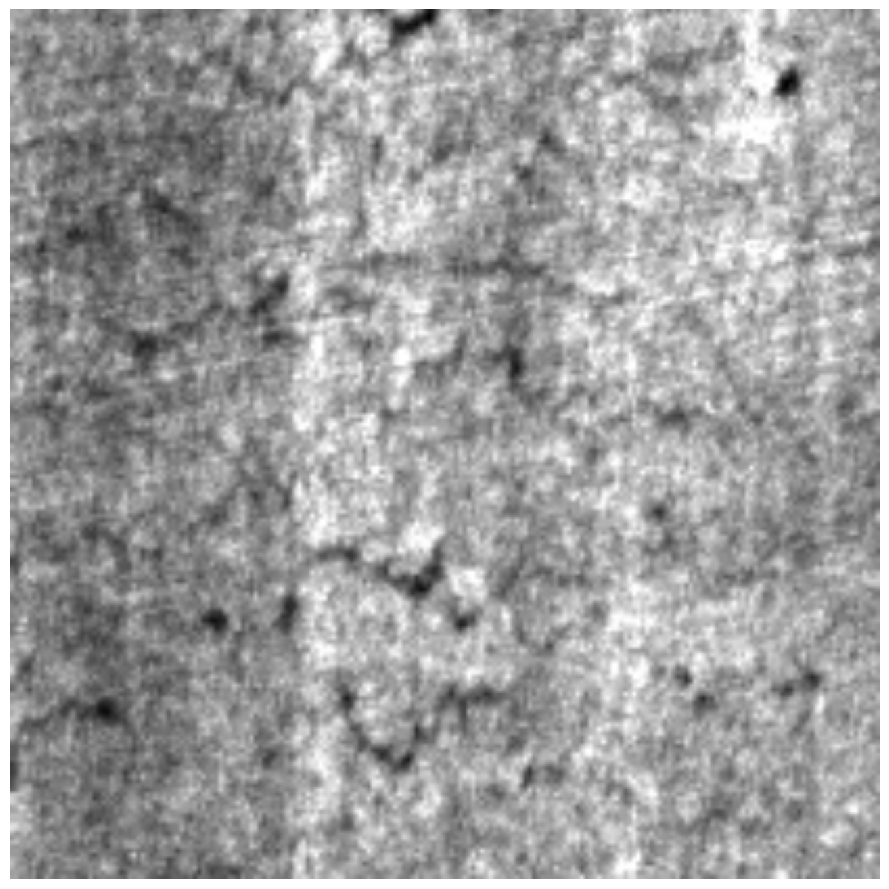


Image 60: Found 2 objects


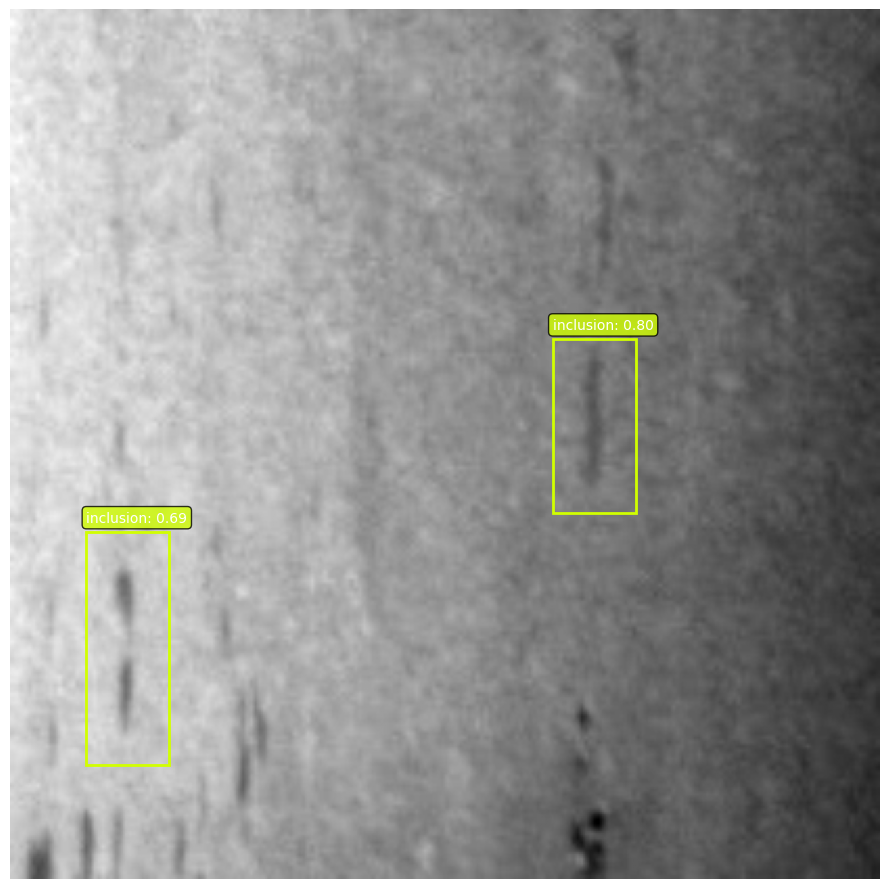


Image 90: Found 2 objects


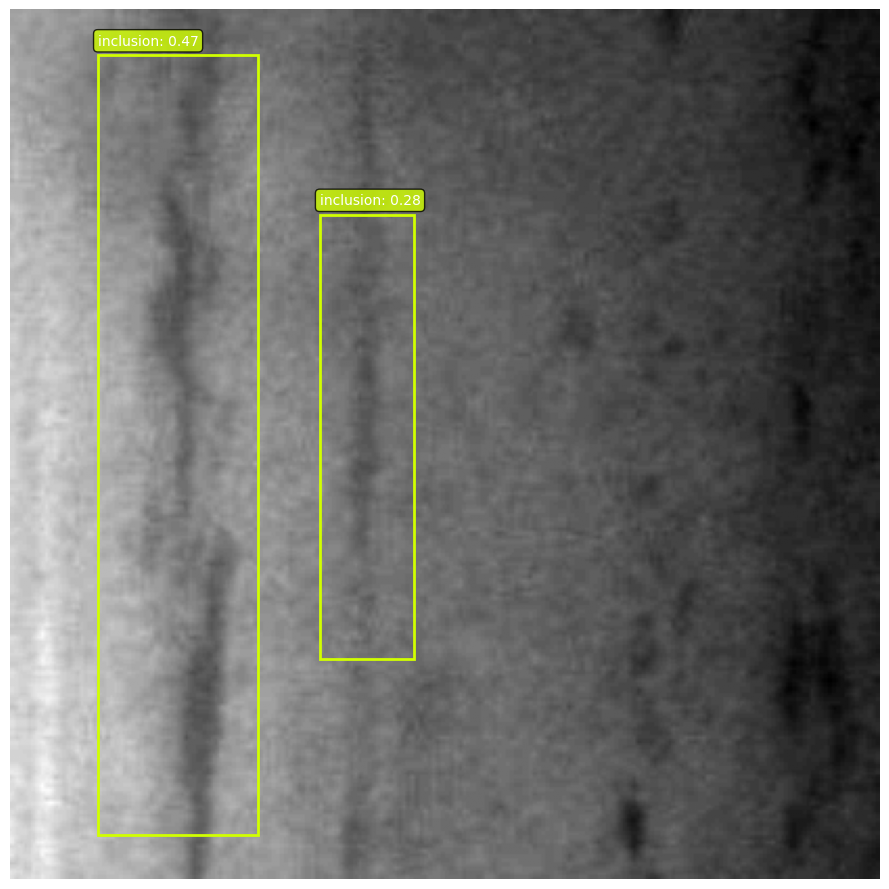


Image 100: Found 2 objects


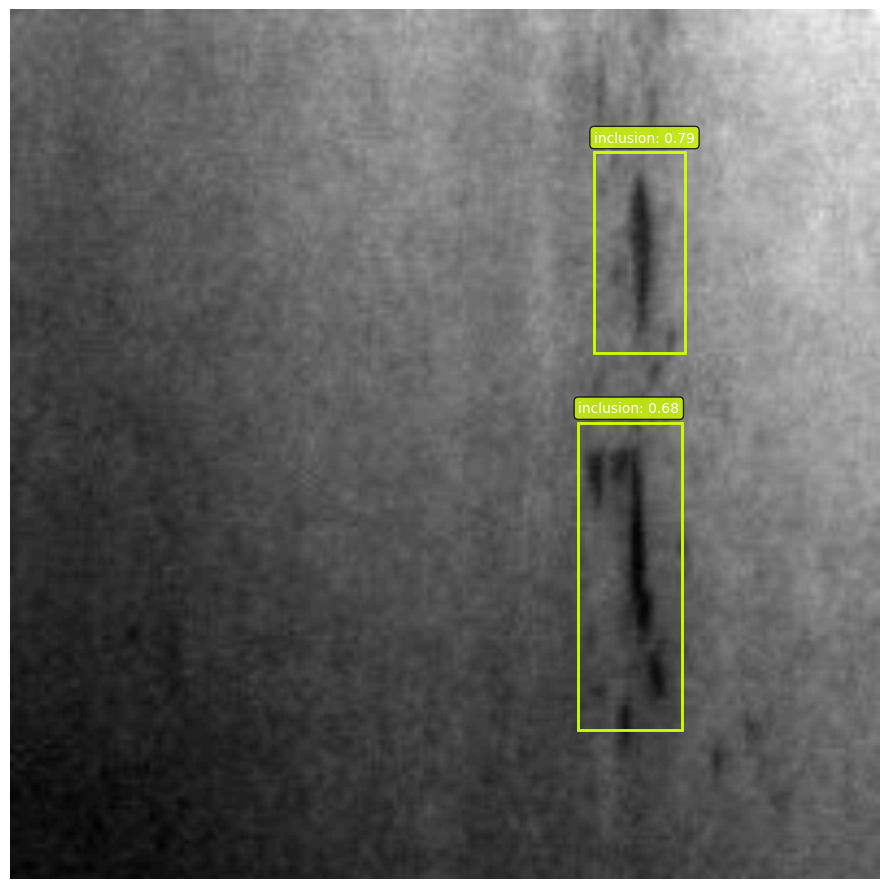


Image 120: Found 2 objects


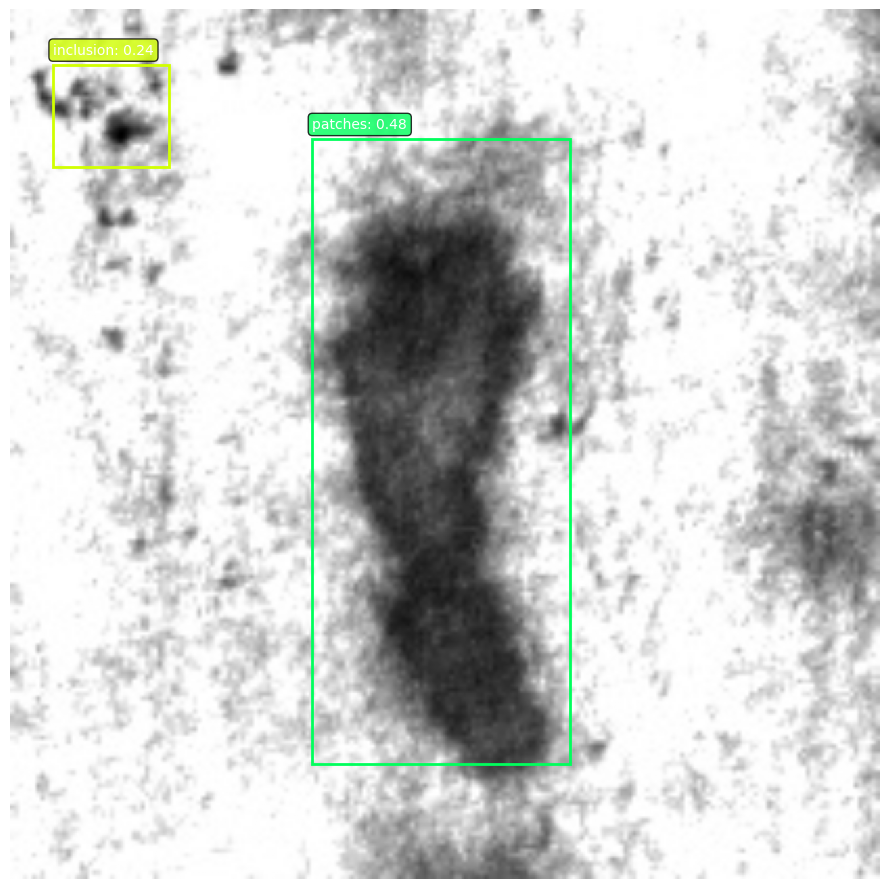


Image 140: Found 5 objects


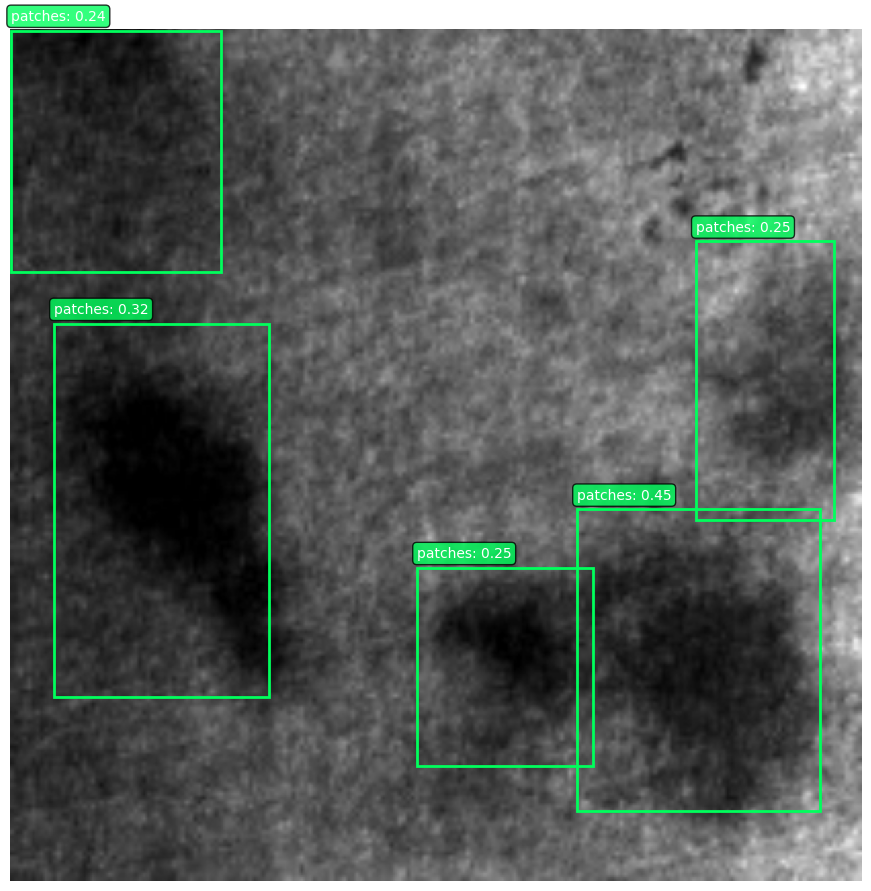


Image 245: Found 1 objects


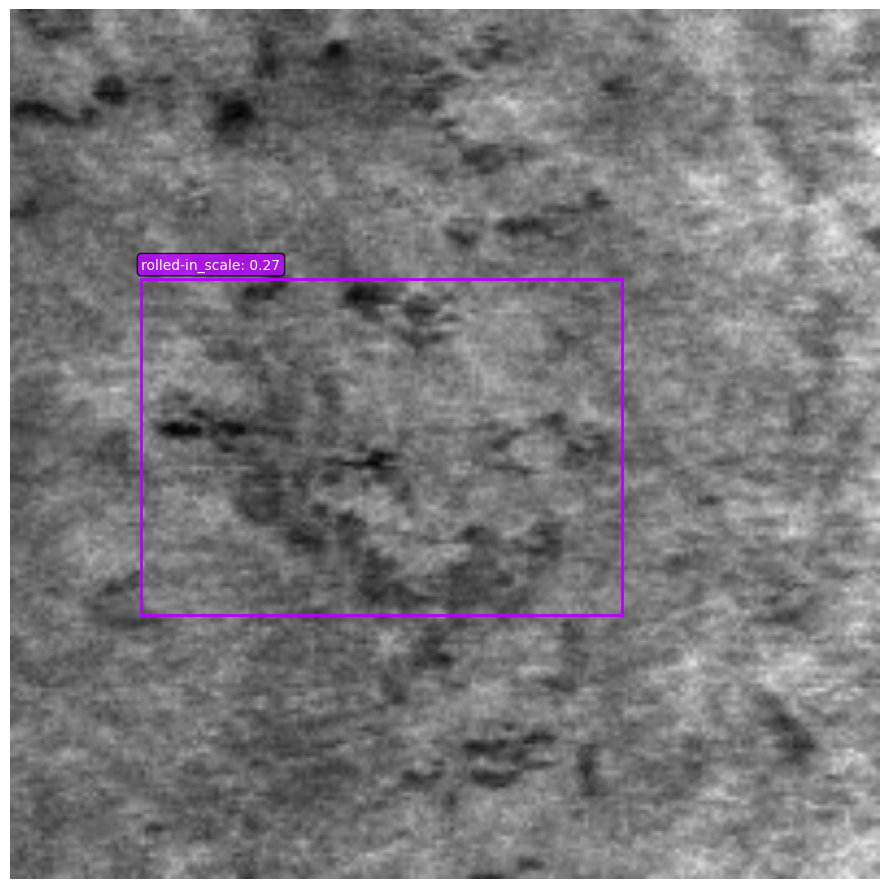


Image 260: Found 1 objects


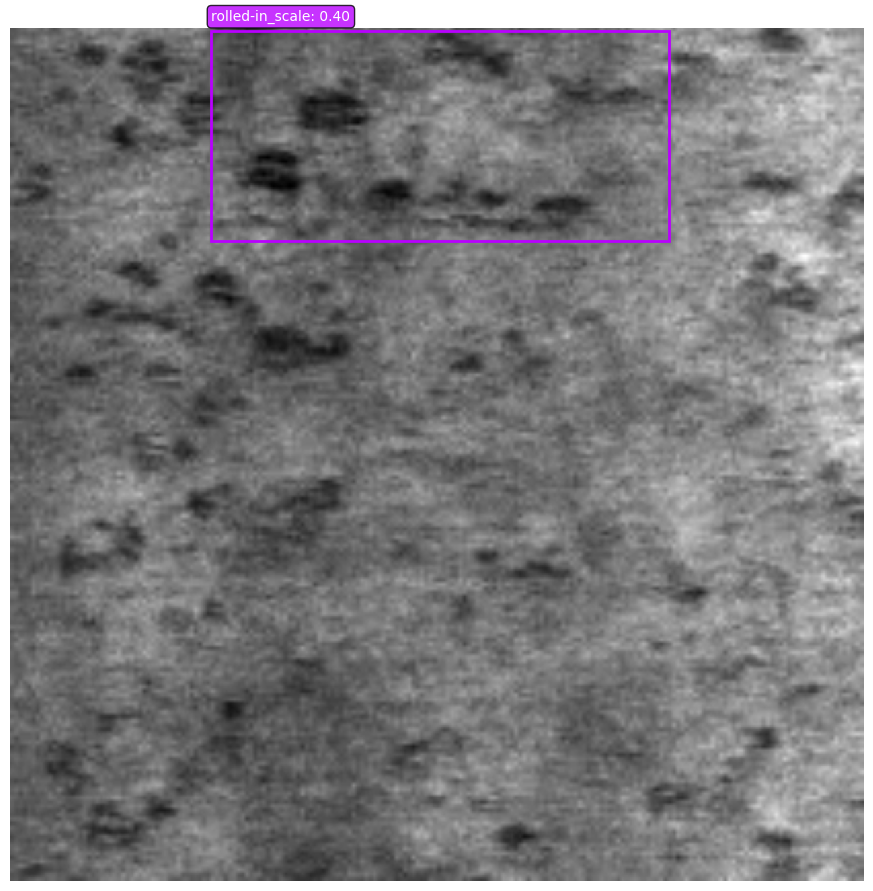


Image 280: Found 2 objects


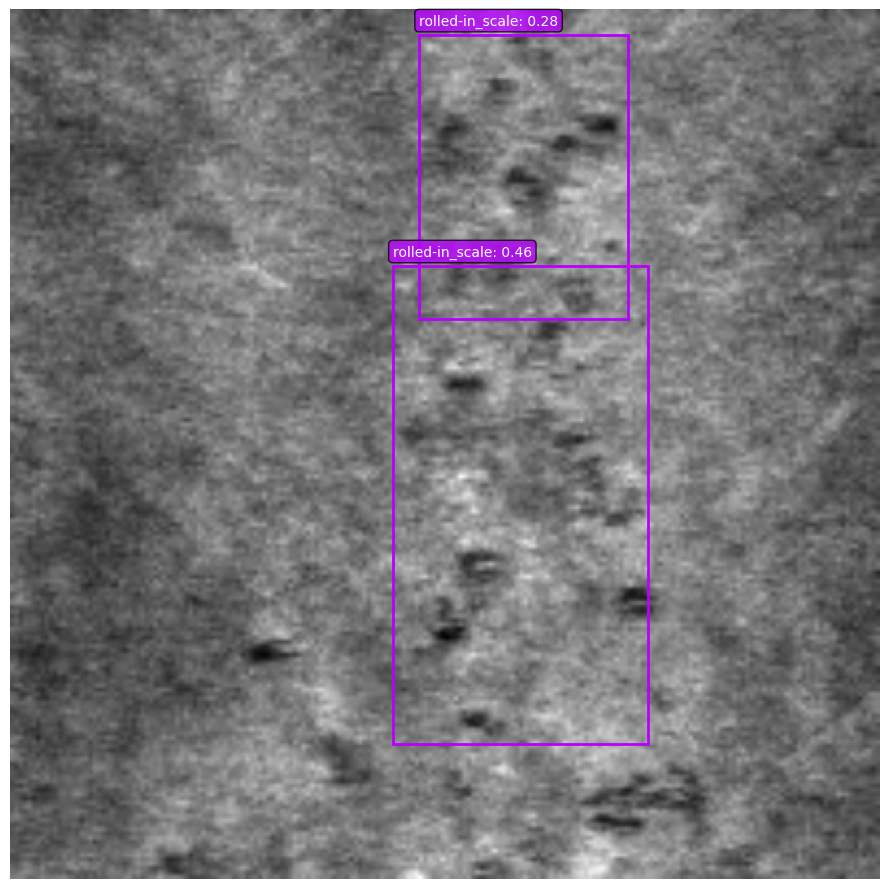


Image 281: Found 2 objects


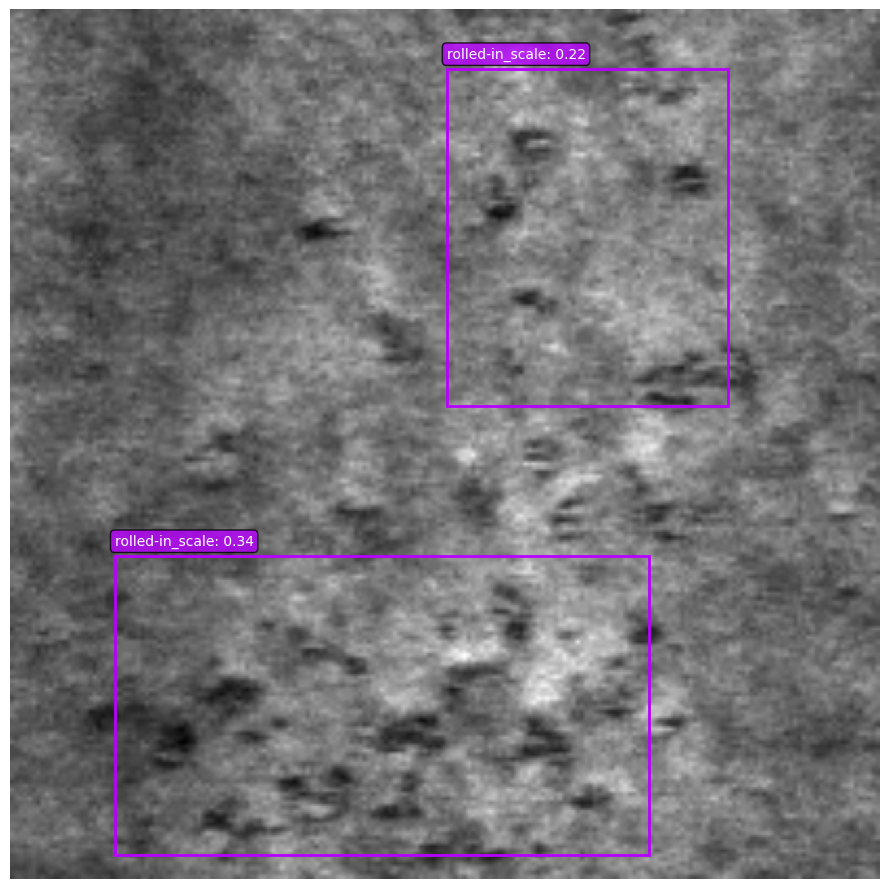


Image 300: Found 3 objects


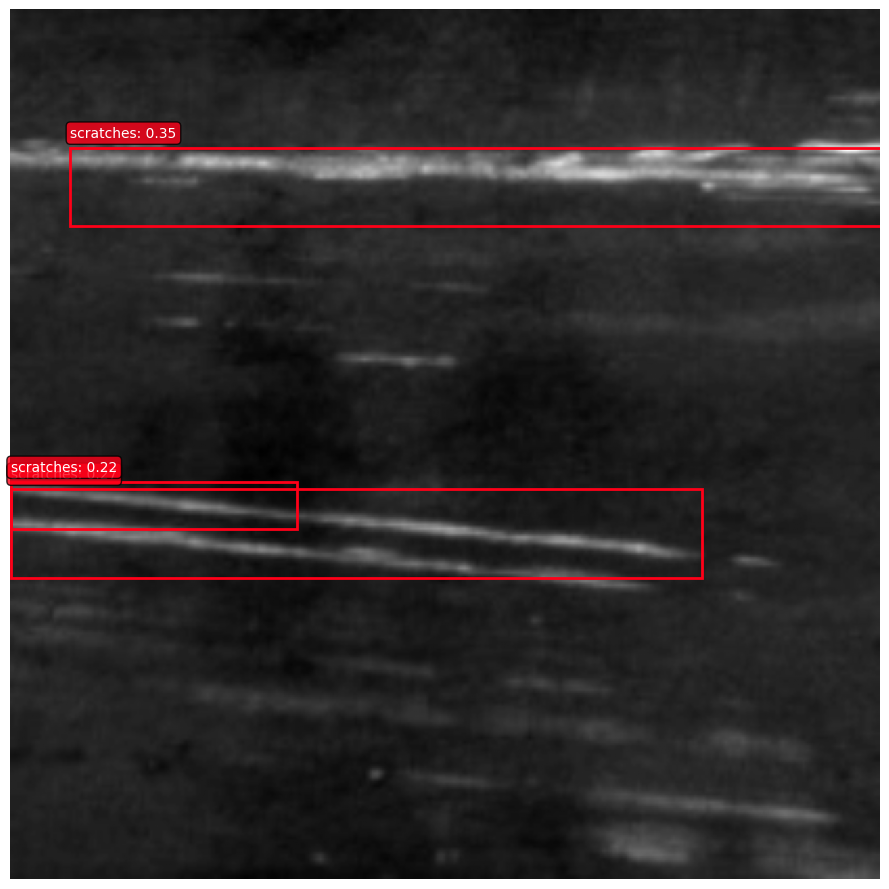


Image 320: Found 1 objects


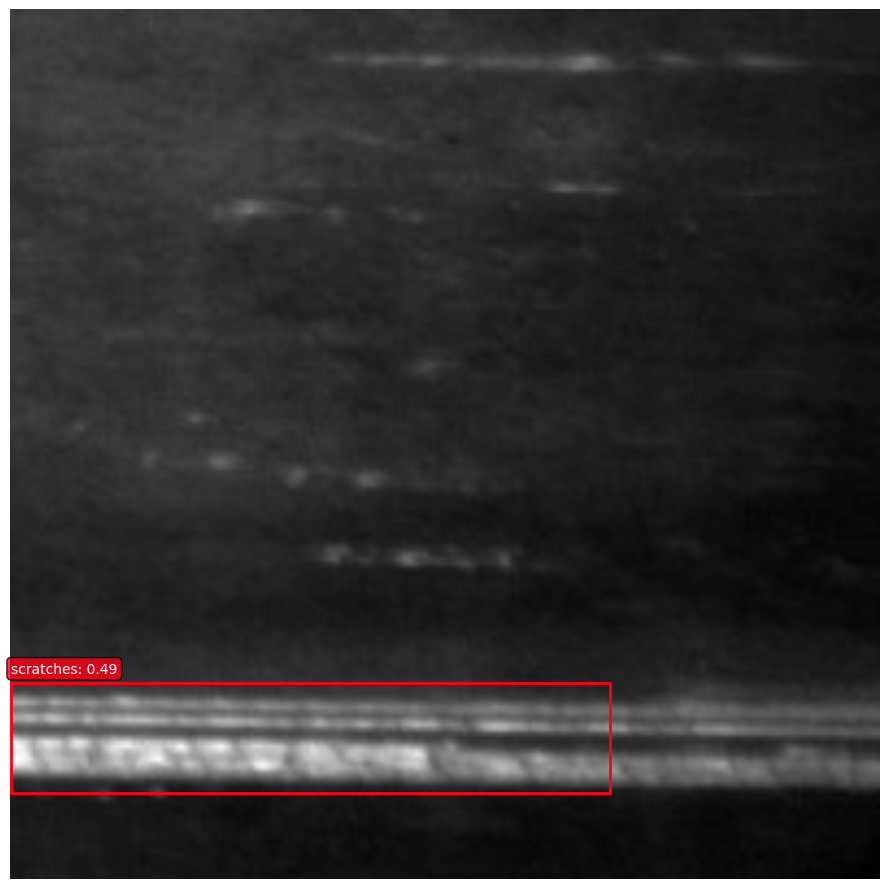


Image 340: Found 2 objects


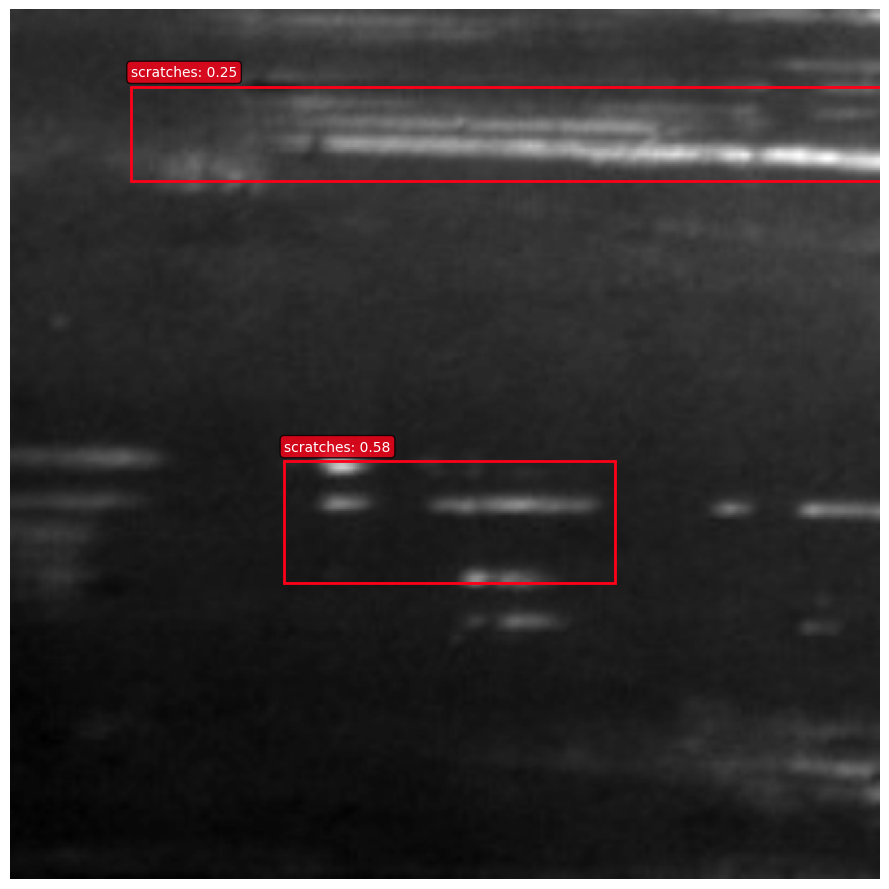

In [13]:
# Load best model and run inference on validation images
checkpoint = torch.load('tiny_yolo_best.pth')
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"Loaded best model from epoch {checkpoint['epoch']+1}")
print(f"Validation loss: {checkpoint['val_loss']:.4f}")

# Get sample images from validation set
sample_indices = [0, 10, 20, 30, 40, 60, 90, 100, 120, 140, 245,260,280,281,300,320,340 ]

for idx in sample_indices:
    if idx >= len(val_dataset):
        continue
    
    # Handle both regular dataset and Subset (from random_split)
    if hasattr(val_dataset, 'dataset'):
        # It's a Subset from random_split
        image, _ = val_dataset.dataset[val_dataset.indices[idx]]
    else:
        image, _ = val_dataset[idx]
    
    image_tensor = image.unsqueeze(0).to(device)
    
    with torch.no_grad():
        predictions = model(image_tensor)
    
    detections = decode_predictions(predictions, ANCHORS, NUM_CLASSES, 
                                    conf_threshold=0.2, nms_threshold=0.2)
    
    print(f"\nImage {idx}: Found {len(detections[0])} objects")
    visualize_detections(image, detections[0], NEU_CLASSES)


## Model Summary

In [14]:
# Print detailed model architecture
print("=" * 70)
print("TINY-YOLO ARCHITECTURE SUMMARY")
print("=" * 70)
print(f"\n{'Layer':<30} {'Output Shape':<25} {'Parameters':>12}")
print("-" * 70)

def count_parameters(module):
    return sum(p.numel() for p in module.parameters())

# Track feature map sizes
test_input = torch.randn(1, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE).to(device)
x = test_input

layers_info = [
    ('Input', test_input.shape, 0),
]

# Layer by layer forward pass for shape tracking
with torch.no_grad():
    x = model.conv1(x)
    layers_info.append((f'Conv1 ({IN_CHANNELS}→16, 3x3)', x.shape, count_parameters(model.conv1)))
    x = model.pool1(x)
    layers_info.append(('MaxPool1 (2x2)', x.shape, 0))
    
    x = model.conv2(x)
    layers_info.append(('Conv2 (16→32, 3x3)', x.shape, count_parameters(model.conv2)))
    x = model.pool2(x)
    layers_info.append(('MaxPool2 (2x2)', x.shape, 0))
    
    x = model.conv3(x)
    layers_info.append(('Conv3 (32→64, 3x3)', x.shape, count_parameters(model.conv3)))
    x = model.pool3(x)
    layers_info.append(('MaxPool3 (2x2)', x.shape, 0))
    
    x = model.conv4(x)
    layers_info.append(('Conv4 (64→128, 3x3)', x.shape, count_parameters(model.conv4)))
    x = model.pool4(x)
    layers_info.append(('MaxPool4 (2x2)', x.shape, 0))
    
    x = model.conv5(x)
    layers_info.append(('Conv5 (128→256, 3x3)', x.shape, count_parameters(model.conv5)))
    x = model.pool5(x)
    layers_info.append(('MaxPool5 (2x2)', x.shape, 0))
    
    x = model.conv6(x)
    layers_info.append(('Conv6 (256→512, 3x3)', x.shape, count_parameters(model.conv6)))
    x = model.pool6(x)
    layers_info.append(('MaxPool6 (2x2, pad)', x.shape, 0))
    
    x = model.conv7(x)
    layers_info.append(('Conv7 (512→1024, 3x3)', x.shape, count_parameters(model.conv7)))
    
    x = model.conv8(x)
    layers_info.append(('Conv8 (1024→256, 1x1)', x.shape, count_parameters(model.conv8)))
    
    x = model.conv9(x)
    layers_info.append(('Conv9 (256→512, 3x3)', x.shape, count_parameters(model.conv9)))
    
    x = model.detection(x)
    layers_info.append((f'Detection (512→{NUM_ANCHORS * (5 + NUM_CLASSES)}, 1x1)', x.shape, count_parameters(model.detection)))

for name, shape, params in layers_info:
    shape_str = str(tuple(shape.tolist()) if hasattr(shape, 'tolist') else shape)
    print(f"{name:<30} {shape_str:<25} {params:>12,}")

print("-" * 70)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"{'Total Parameters:':<55} {total_params:>12,}")
print(f"{'Trainable Parameters:':<55} {trainable_params:>12,}")
print(f"{'Model Size (MB):':<55} {total_params * 4 / 1024**2:>12.2f}")
print("=" * 70)


TINY-YOLO ARCHITECTURE SUMMARY

Layer                          Output Shape                Parameters
----------------------------------------------------------------------
Input                          torch.Size([1, 1, 416, 416])            0
Conv1 (1→16, 3x3)              torch.Size([1, 16, 416, 416])          176
MaxPool1 (2x2)                 torch.Size([1, 16, 208, 208])            0
Conv2 (16→32, 3x3)             torch.Size([1, 32, 208, 208])        4,672
MaxPool2 (2x2)                 torch.Size([1, 32, 104, 104])            0
Conv3 (32→64, 3x3)             torch.Size([1, 64, 104, 104])       18,560
MaxPool3 (2x2)                 torch.Size([1, 64, 52, 52])            0
Conv4 (64→128, 3x3)            torch.Size([1, 128, 52, 52])       73,984
MaxPool4 (2x2)                 torch.Size([1, 128, 26, 26])            0
Conv5 (128→256, 3x3)           torch.Size([1, 256, 26, 26])      295,424
MaxPool5 (2x2)                 torch.Size([1, 256, 13, 13])            0
Conv6 (256→512, 3x3)